[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mbontrid/SRN-statistical-learning-experimentation/blob/main/notebook/srn_analysis.ipynb)

In [23]:
import json
import numpy as np
from typing import IO
from models.srn import SRN
from itertools import product
import random

from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
import matplotlib.animation as animation


import pandas as pd

from dataclasses import dataclass, field


# Data import and processing

## Data import

The imported file is a .json file with "extracted_sequences" as root key. The associated value is the list of 3-letters sequences (although sequences size should not be of any importance on the programming side). 

In [24]:
with open("data/extracted_sequences.json") as fp:
    sequences = json.load(fp)["extracted_sequences"]

random.shuffle(sequences)

## Dataset vocabulary

Uses a custom dataclass to extract vocabulary data in the dataet

In [25]:
@dataclass
class Vocab:
    """Bidirectional token ↔ index mapping."""
    token_to_idx: dict[str, int] = field(default_factory=dict)
    idx_to_token: dict[int, str] = field(default_factory=dict)
    alphabet: set[str] = field(default_factory=set)
    size: int = 0


def build_vocab(sequences: list[list[str]]) -> Vocab:
    """Build a :class:`Vocab` from a list of token sequences."""
    tokens = sorted({token for seq in sequences for token in seq})
    token_to_idx = {t: i for i, t in enumerate(tokens)}
    idx_to_token = {i: t for t, i in token_to_idx.items()}
    alphabet = build_alphabet(sequences)
    return Vocab(token_to_idx=token_to_idx, idx_to_token=idx_to_token, size=len(tokens), alphabet=alphabet)

def build_alphabet(sequences: list[list[str]]) -> set[str]:
    """Extracts the alphabet in the set of sequences"""
    return set([letter for sequence in sequences for letter in sequence])


def load_sequences(file: IO[bytes]) -> list[list[str]]:
    """Parse a JSON dataset file and return its ``extracted_sequences`` field."""
    data = json.load(file)
    return data["extracted_sequences"]


def one_hot(token: str, vocab: Vocab) -> np.ndarray:
    """Return a one-hot vector for *token* using *vocab*."""
    vec = np.zeros(vocab.size)
    vec[vocab.token_to_idx[token]] = 1.0
    return vec

## Strings generation

Generates a set of string of desired size following the rule mapping first token to third token.

In [26]:
import random
import string

def generate_strings(n, second_letter_alphabet_size=6):
    """
    Generate n strings of length 3 following these rules:
    - if first letter is 'a', third letter is 'd'
    - if first letter is 'b', third letter is 'e'
    - if first letter is 'c', third letter is 'f'
    - second letter is randomly chosen from a configurable alphabet
    """

    # Mapping between first and third letters
    mapping = {
        'a': 'd',
        'b': 'e',
        'c': 'f'
    }

    # Available letters for the second position
    # Example: size=5 -> ['G', 'H', 'I', 'J', 'K']
    second_letter_alphabet = string.ascii_uppercase[6:6+second_letter_alphabet_size]

    results = []

    for _ in range(n):
        first = random.choice(list(mapping.keys()))
        second = random.choice(second_letter_alphabet)
        third = mapping[first]

        results.append([first, second, third])

    return results




### Generate datasets

Generates two sets of data (alphabet size for second position = 20 and 6)

In [28]:
x = 1000 # Change this to adapt the number of sequences
ALPHABET_SIZE = 6 # Change this to adapt variability on the second token

generated_second = generate_strings(x, ALPHABET_SIZE)

with open(f'data/generated_var_{ALPHABET_SIZE}.json', 'w') as fp:
    json.dump({'extracted_sequences': generated_second}, fp)

In [27]:
x = 1000 # Change this to adapt the number of sequences
ALPHABET_SIZE = 12 # Change this to adapt variability on the second token

generated_first = generate_strings(x, ALPHABET_SIZE)

with open(f'data/generated_var_{ALPHABET_SIZE}.json', 'w') as fp:
    json.dump({'extracted_sequences': generated_first}, fp)

In [27]:
x = 1000 # Change this to adapt the number of sequences
ALPHABET_SIZE = 22 # Change this to adapt variability on the second token

generated_first = generate_strings(x, ALPHABET_SIZE)

with open(f'data/generated_var_{ALPHABET_SIZE}.json', 'w') as fp:
    json.dump({'extracted_sequences': generated_first}, fp)

### Select dataset

Choose different datasets

- Keep everything commented: Use imported dataset (180 sequences, alphabet-size for 2nd position = 15)
- Uncomment one of the two lines: Choose the corresponding generated dataset

In [29]:
sequences = generated_first
#sequences = generated_second

### Build vocab for tokens handling

In [30]:
vocab = build_vocab(sequences)

# Training Helpers

Training occurs as follows:
- The modelis trained on a letter in the current sequence
- Once trained on this letter, the hidden states are collected
- The training step is repeated on each letter in each sequence
- The context is never reset, the sequence is considered as a single stream

In [31]:
def train(sequences, model):
    """Yield *(hidden states, labels)* after each input."""  
    
    total_loss = 0.0

    for sequence_number, seq in enumerate(sequences):

        if sequence_number == len(sequences) - 1:
            continue

        sequence_length = len(seq)

        for i in range(len(seq)):
            
            current_token = seq[i]
            
            x = one_hot(seq[i], vocab)
                
            if i < sequence_length - 1:
                target = one_hot(seq[i + 1], vocab)
            elif sequence_number < len(sequences) - 1:
                target = one_hot(sequences[sequence_number + 1][0], vocab)
            else:
                continue
                
            total_loss += model.train_step(x, target)
                
            yield collect_hidden_states(sequences, current_token)

def collect_hidden_states(sequences, previous_token):
        """Run all sequences through the model and collect hidden states for each prediction."""

        states = {}
        labels: list[tuple[str, str]] = []

        for token in vocab.alphabet:
            x = one_hot(token, vocab)
            h, y = model.forward(x)
            predicted = vocab.idx_to_token[int(np.argmax(y))]
            states[(previous_token, token)] = h.flatten()
            labels.append((token, predicted))

        return np.array(states)

def test_model(test_set):

    scores = [{'true': 0, 'false': 0} for i in range(len(test_set[0]))]

    ncount = 0

    for sequence_number, seq in enumerate(test_set):

        if sequence_number == len(test_set) - 1:
            continue

        sequence_length = len(seq)

        for i in range(len(seq)):
            x = one_hot(seq[i], vocab)
            h, y = model.forward(x)
            predicted = vocab.idx_to_token[int(np.argmax(y))]

            model.update_context(h)
                
            if i < sequence_length - 1:
                target = seq[i + 1]
            elif sequence_number < len(test_set) - 1:
                target = test_set[sequence_number + 1][0]
            else:
                continue

            if predicted == target:
                scores[(i + 1) % sequence_length]['true'] += 1
            else:
                scores[(i + 1) % sequence_length]['false'] += 1 
                
    return scores

# Model definition

SRN requires the following list of paramerters:
- "hidden_size": Number of neurons in the hidden layer,
- "lr": larning rate, portion of the gradient used to update the wheights at each step,
- "mu": portion of the pattern of activation copied from the context layer,
- "clearval": default value of the activations of the context units, used to reset the context units between each sequence

In [20]:
params = {
    "hidden_size": 20,
    "lr": 0.05, 
    "mu": 0.,
    "clearval": 0.,
    "vocab_size":  vocab.size
   }

model = SRN(params)

{'hidden_size': 20, 'lr': 0.05, 'mu': 0.0, 'clearval': 0.0, 'vocab_size': 26}


# Training

## Single network training

Splits dataset in train and test sets

In [21]:
train_set, test_set = sequences[:120], sequences[120:]

In [22]:
all_epochs = []

for i in range(30):
    res = [elt for elt in train(train_set, model)]
    all_epochs.append(res)
    scores = test_model(test_set)
    percent_correct = {}
    for position, score in enumerate(scores):
        percent_correct[position + 1] = round(((score['true'] / (score['true'] + score['false'])) * 100), 2)
    print(percent_correct)

all_steps = [step for epoch in all_epochs for step in epoch]



{1: 34.58, 2: 0.0, 3: 9.78}
{1: 30.38, 2: 5.35, 3: 48.46}
{1: 30.38, 2: 5.35, 3: 58.82}
{1: 30.38, 2: 5.35, 3: 69.85}
{1: 30.38, 2: 5.57, 3: 82.25}
{1: 30.38, 2: 4.89, 3: 88.96}
{1: 30.72, 2: 4.44, 3: 94.65}
{1: 30.38, 2: 4.78, 3: 99.2}
{1: 30.94, 2: 4.66, 3: 100.0}
{1: 31.97, 2: 4.66, 3: 100.0}
{1: 32.08, 2: 4.55, 3: 100.0}
{1: 32.42, 2: 4.89, 3: 100.0}
{1: 32.54, 2: 4.66, 3: 100.0}
{1: 32.42, 2: 4.66, 3: 100.0}
{1: 32.42, 2: 4.66, 3: 100.0}
{1: 32.42, 2: 4.66, 3: 100.0}
{1: 32.42, 2: 4.66, 3: 100.0}
{1: 32.65, 2: 4.55, 3: 100.0}
{1: 33.11, 2: 4.32, 3: 100.0}
{1: 31.97, 2: 4.1, 3: 100.0}
{1: 31.06, 2: 4.32, 3: 100.0}
{1: 31.63, 2: 4.21, 3: 100.0}
{1: 32.65, 2: 4.1, 3: 100.0}
{1: 31.74, 2: 4.1, 3: 100.0}
{1: 32.2, 2: 4.78, 3: 100.0}
{1: 32.42, 2: 4.66, 3: 100.0}
{1: 32.76, 2: 4.66, 3: 100.0}
{1: 32.88, 2: 4.78, 3: 100.0}
{1: 32.88, 2: 5.12, 3: 100.0}
{1: 32.76, 2: 5.35, 3: 99.89}


### Set timestep for analysis

Here, a timestep corresponds to a training step on a single example. All epochs are treated sequentially and stored in a flattened array.

Example:
If we have a dataset with **100 sequences of 3 tokens** and **10 epochs**, the array will contain approximately **3x100x10 = 3000 timesteps**

In [82]:
TIME_STEP = -2

### Distance Heatmap

#### Heatmap implementation

Function to plot the heatmap of pairwise distances between hidden states

In [83]:
import numpy as np
import matplotlib.pyplot as plt
 
 
def plot_heatmap(res, save_path=None):
    """
    Plot cosine similarity heatmap.
    
    Args:
        res: List of results from train() function
        save_path: Optional path to save the figure
    """
    
    # Extract keys and values, maintaining initial order
    keys = list(d.keys())  # These are tuples: (previous_token, next_token)
    vectors = np.array(list(d.values()))
    
    # Sort by second element (index 1) of tuple in DECREASING order
    # This creates indices sorted by the second letter: Z > M > A
    sorted_indices = sorted(
        range(len(keys)), 
        key=lambda i: keys[i][1]
    )
    
    # Reorder ALL components using the same indices
    # This is CRITICAL: keys, vectors, and labels must be in the same order
    sorted_keys = [keys[i] for i in sorted_indices]
    sorted_vectors = vectors[sorted_indices]
    
    # Create labels from sorted keys
    labels = [f"{k[0]}-{k[1]}" for k in sorted_keys]
    
    # Normalize vectors
    norms = np.linalg.norm(sorted_vectors, axis=1, keepdims=True)
    # Add small epsilon to prevent division by zero
    normalized = sorted_vectors / (norms + 1e-10)
    
    # Compute cosine similarity matrix
    # Now the rows/columns of sim_matrix correspond to labels in sorted order
    sim_matrix = normalized @ normalized.T
    
    # Create the heatmap
    fig, ax = plt.subplots(figsize=(14, 14))
    im = ax.imshow(sim_matrix, cmap='Blues', aspect='auto')
    
    # Set axis ticks
    ax.set_xticks(np.arange(len(labels)))
    ax.set_yticks(np.arange(len(labels)))
    
    # Set tick labels with reduced fontsize to accommodate many labels
    ax.set_xticklabels(labels, rotation=90, fontsize=7)
    ax.set_yticklabels(labels, fontsize=7)
    
    # Add colorbar
    cbar = plt.colorbar(im, ax=ax)
    cbar.set_label("Cosine Similarity", fontsize=11)
    
    # Add values inside cells
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(
                j, i,
                f"{sim_matrix[i, j]:.2f}",
                ha="center",
                va="center",
                fontsize=4  # Very small since there are many cells
            )
    
    ax.set_title(
        "Cosine Similarity Heatmap",
        fontsize=14,
        fontweight='bold'
    )
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Figure saved to {save_path}")
    
    plt.show()
    
    # Return sorting info for verification
    return {
        'original_keys': keys,
        'sorted_keys': sorted_keys,
        'labels': labels,
        'sorted_indices': sorted_indices
    }

#### Distances heatmap plot 

10710


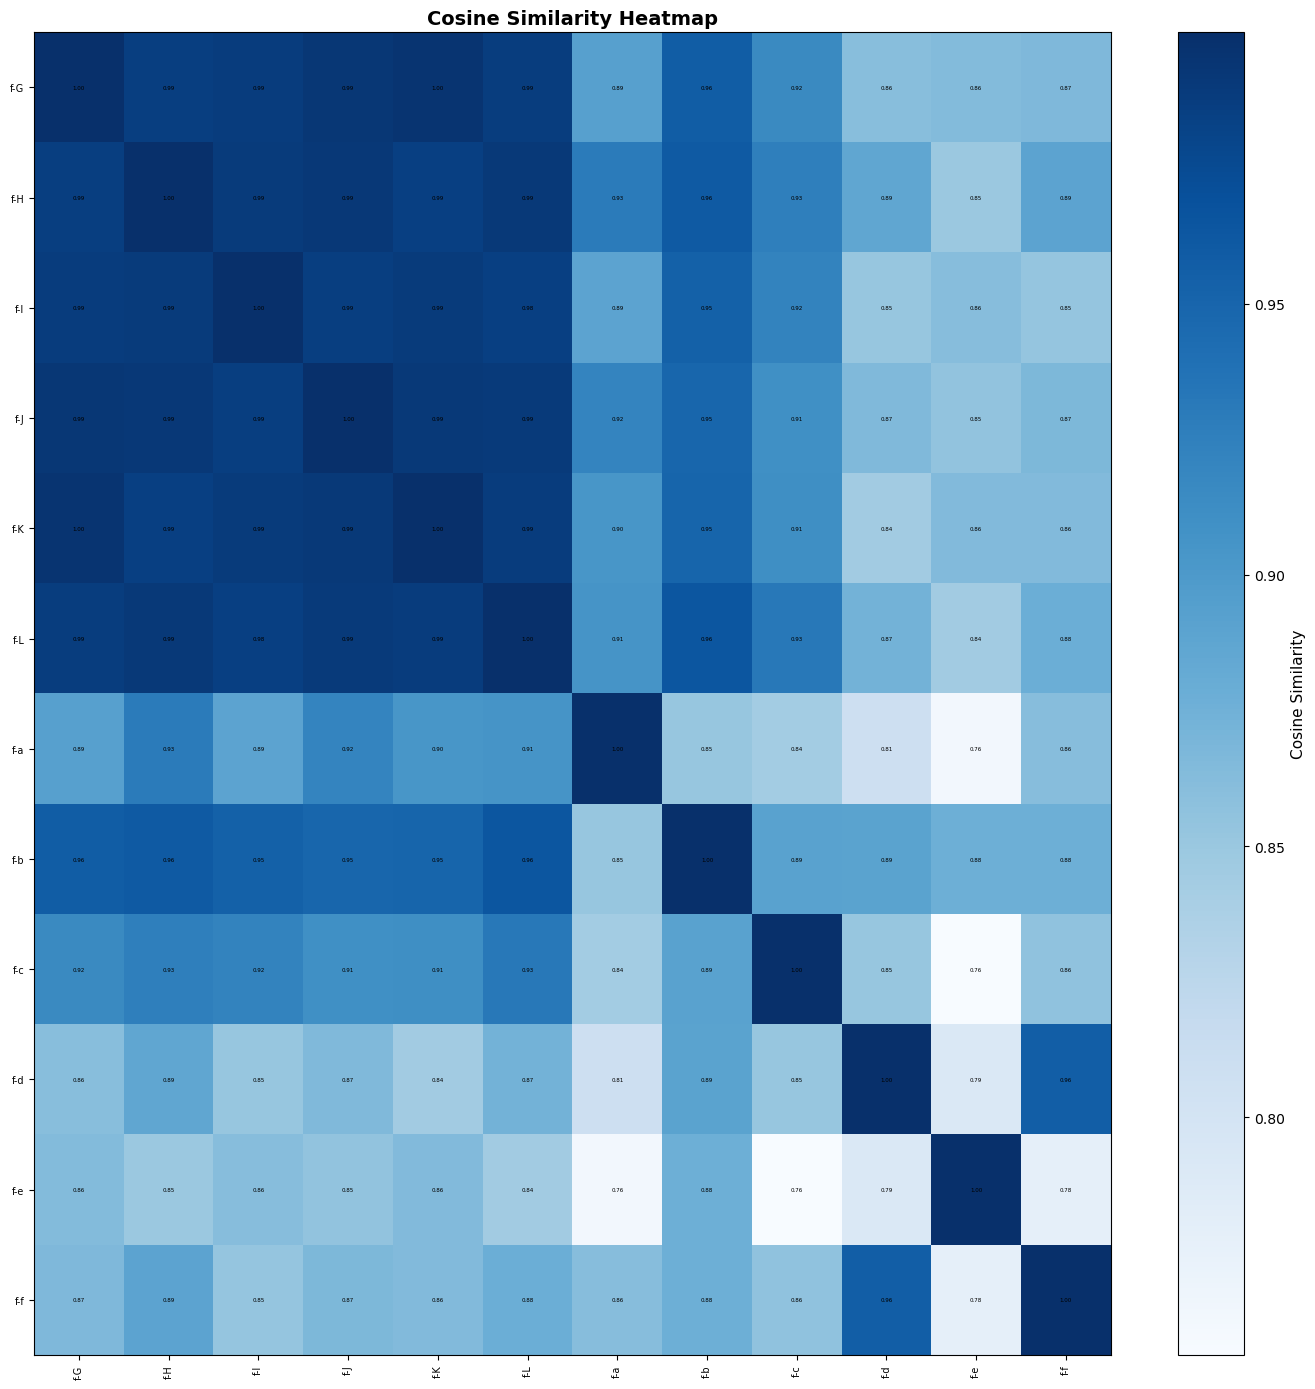

In [84]:
print(len(all_steps))
d = all_steps[-1].item()
_ = plot_heatmap(res, save_path=None)

### PCA

PCA is a dimensionality reduction algorithm used to embed high dimension data into 2D representations by finding the representation that maximizes the variance on these two axes.

It allows to visualize similarity in the data.

(12, 20)
(12, 2)


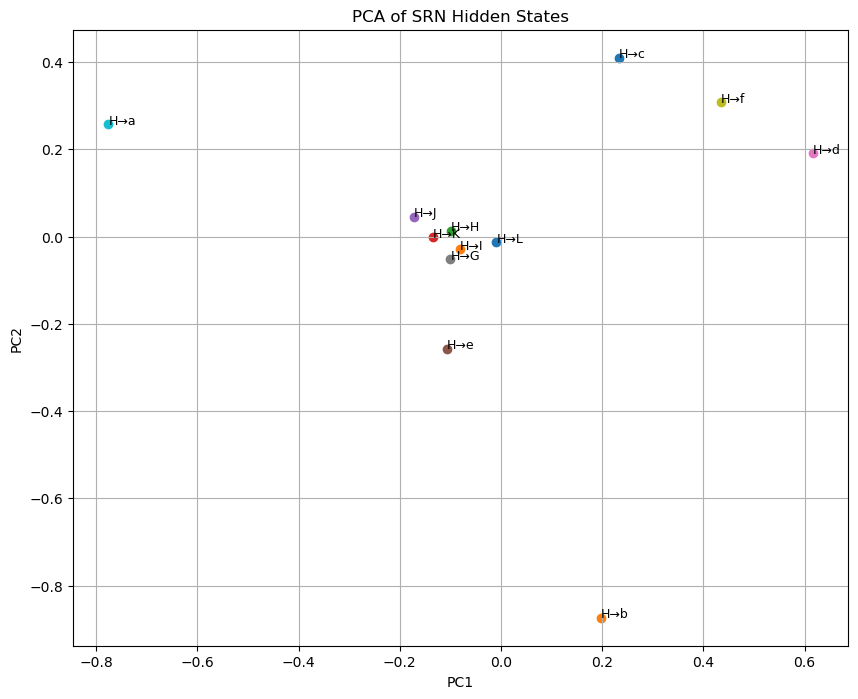

In [85]:
d = all_steps[TIME_STEP].item()

# your dictionary
hidden_states = d

# ------------------------------------------------------------------
# 1. Extract labels and vectors
# ------------------------------------------------------------------

pairs = list(hidden_states.keys())

X = np.array([
    hidden_states[pair]
    for pair in pairs
])

# X shape: (num_pairs, hidden_size)

print(X.shape)

# ------------------------------------------------------------------
# 2. Run PCA
# ------------------------------------------------------------------

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X)

print(X_pca.shape)

# ------------------------------------------------------------------
# 3. Visualize
# ------------------------------------------------------------------

plt.figure(figsize=(10, 8))

for i, pair in enumerate(pairs):
    x, y = X_pca[i]

    label = f"{pair[0]}→{pair[1]}"

    plt.scatter(x, y)
    plt.text(x, y, label, fontsize=9)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA of SRN Hidden States")
plt.grid(True)

plt.show()

### Compute distance of a pair from the rest of the points

Here, we compute the distance from one point to the mean  of the others.

Hypothesis:
If a point is more likely to be learned efficiently, it should be more distant to the barycentre than the rest of the points

The distance between points and prediction accuracy does not seem to completely correlate, so this hypothesis is probably not completely correct, but it should give an idea on **training convergence**

#### Single timestep visualization

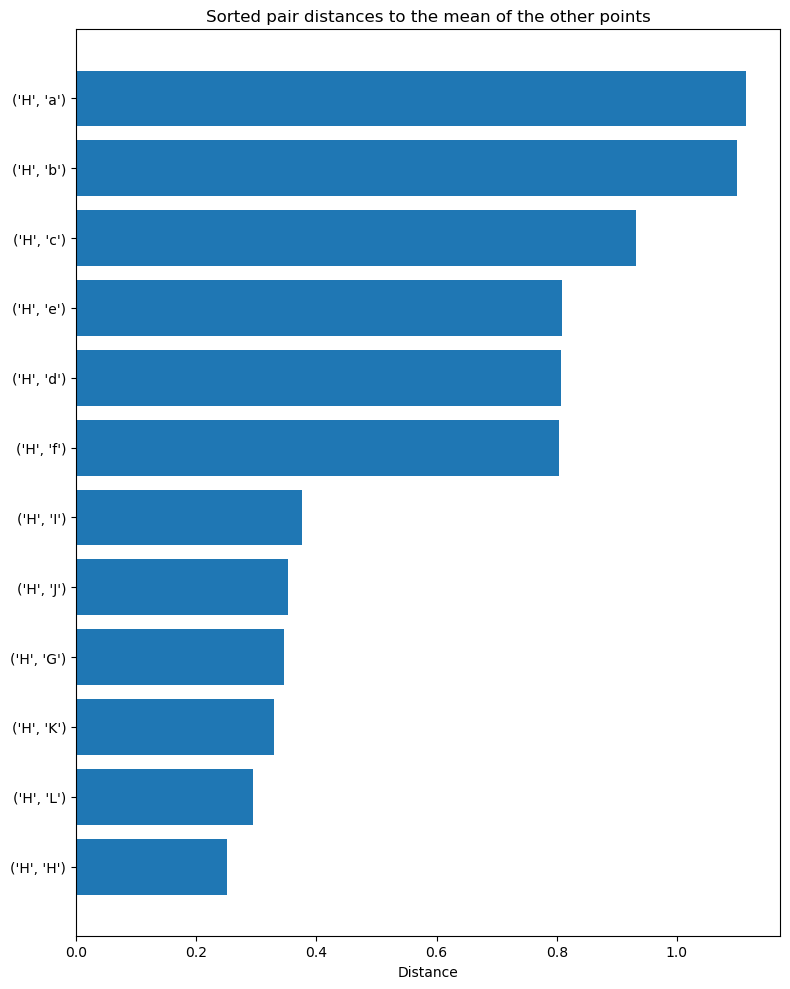

In [86]:
import numpy as np

# keys and vectors
keys = list(d.keys())
X = np.stack([d[k] for k in keys])   # shape: (n_pairs, dim)

n = len(keys)

# sum of all vectors
total = X.sum(axis=0)

distances = {}

for i, k in enumerate(keys):
    x_i = X[i]

    # mean of all OTHER vectors
    mean_others = (total - x_i) / (n - 1)

    # Euclidean distance
    dist = np.linalg.norm(x_i - mean_others)

    distances[k] = dist

sorted_items = sorted(distances.items(), key=lambda x: x[1])

pairs = [str(k) for k, _ in sorted_items]
vals = [v for _, v in sorted_items]

plt.figure(figsize=(8, 10))
plt.barh(pairs, vals)

plt.xlabel("Distance")
plt.title("Sorted pair distances to the mean of the other points")
plt.tight_layout()
plt.show()

#### Distances through time

In [90]:
"""
Extracts timesteps in a dataframe for later processing
"""

all_distances = []

for t, d in enumerate(all_steps):

    keys = list(d.item().keys())
    X = np.stack([d.item()[k] for k in keys])

    total = X.sum(axis=0)
    n = len(keys)

    for i, k in enumerate(keys):

        mean_others = (total - X[i]) / (n - 1)

        dist = np.linalg.norm(X[i] - mean_others)

        all_distances.append({
            "time": t,
            "pair": str(k),
            "distance": dist
        })

df = pd.DataFrame(all_distances)

In [92]:
pivot

time,0,1,2,3,4,5,6,7,8,9,...,10700,10701,10702,10703,10704,10705,10706,10707,10708,10709
pair,,,,,,,,,,,,,,,,,,,,,
"('G', 'G')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"('G', 'H')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"('G', 'I')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"('G', 'J')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
"('G', 'K')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
"('f', 'b')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.214256,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.781390
"('f', 'c')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.281864,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.734166
"('f', 'd')",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.264473,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.783018


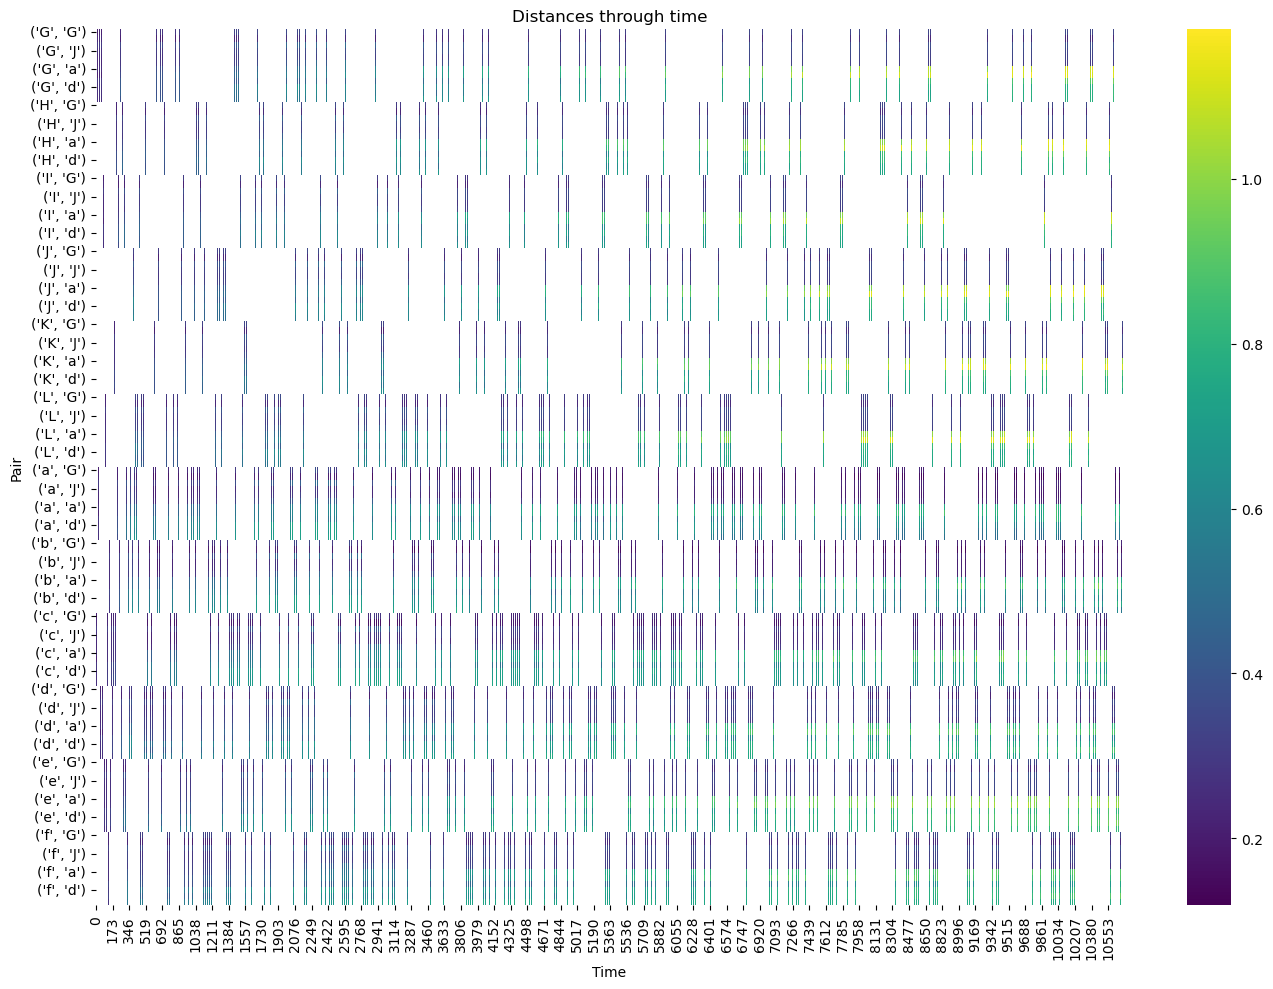

In [88]:
import seaborn as sns

pivot = df.pivot(index="pair", columns="time", values="distance")

plt.figure(figsize=(14, 10))
sns.heatmap(pivot, cmap="viridis")

plt.title("Distances through time")
plt.xlabel("Time")
plt.ylabel("Pair")

plt.tight_layout()
plt.show()

#### Z-scores through time

In [89]:
df["zscore"] = (
    df.groupby("pair")["distance"]
      .transform(lambda x: (x - x.mean()) / x.std())
)

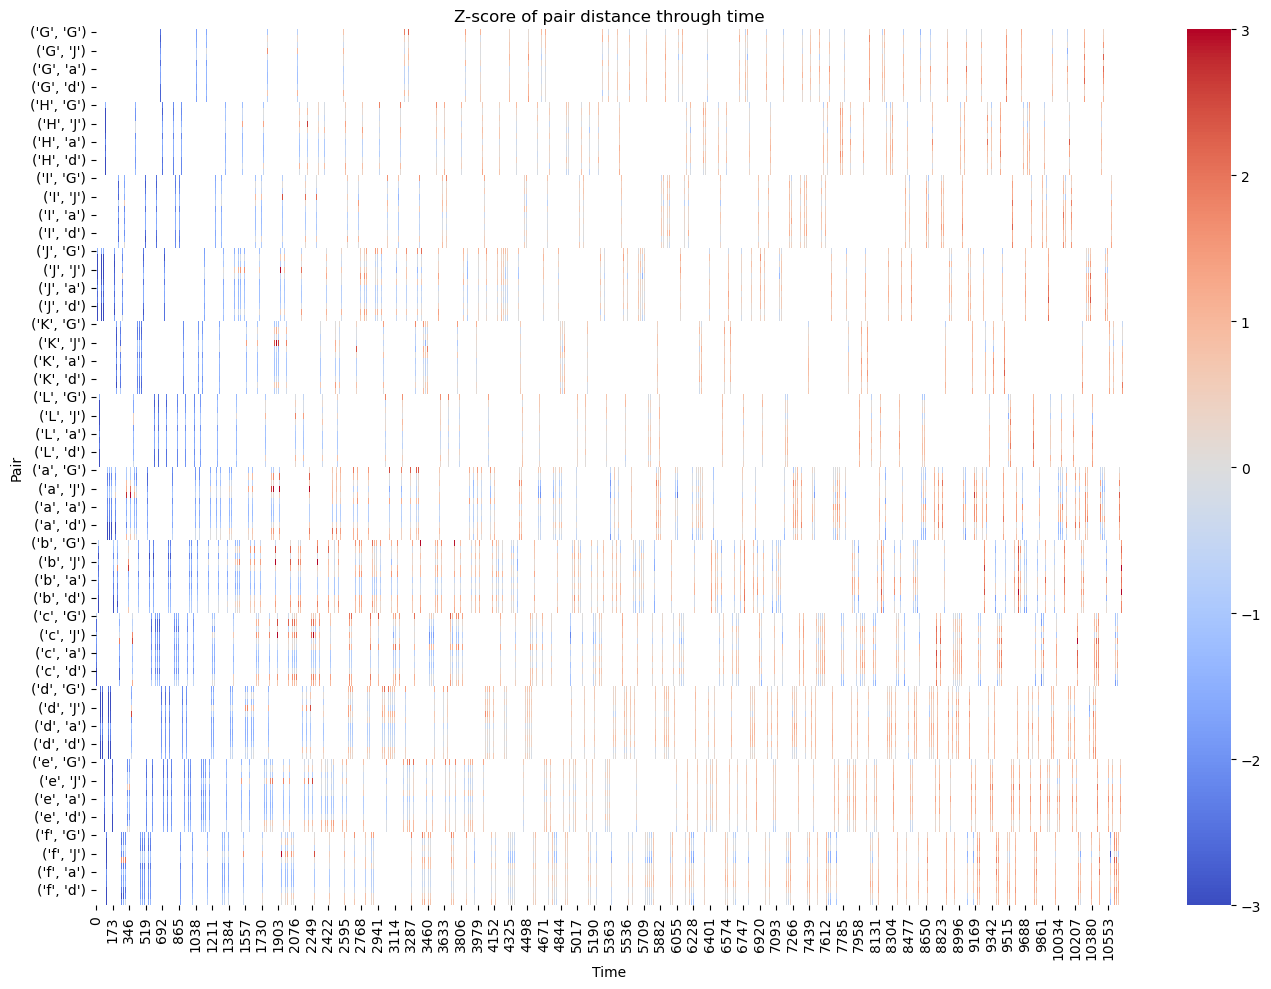

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns

pivot = df.pivot(index="pair", columns="time", values="zscore")

plt.figure(figsize=(14, 10))

sns.heatmap(
    pivot,
    cmap="coolwarm",
    center=0,
    vmin=-3,
    vmax=3
)

plt.title("Z-score of pair distance through time")
plt.xlabel("Time")
plt.ylabel("Pair")

plt.tight_layout()
plt.show()

In [67]:
df[df['time'] == 0]

,time,pair,distance,zscore,rolling_z
0,0,"('b', 'L')",0.249853,-2.393187,NaN
1,0,"('b', 'I')",0.263741,-3.033682,NaN
2,0,"('b', 'H')",0.220409,-2.197010,NaN
3,0,"('b', 'K')",0.182996,-2.554159,NaN
4,0,"('b', 'J')",0.294870,-1.956814,NaN
5,0,"('b', 'e')",0.298938,-4.325527,NaN
6,0,"('b', 'd')",0.277055,-3.308503,NaN
7,0,"('b', 'G')",0.252665,-0.707245,NaN
8,0,"('b', 'f')",0.316707,-5.036078,NaN
9,0,"('b', 'a')",0.251927,-1.983356,NaN


#### Rolling z-scores through time

In [59]:
window = 20

df["rolling_z"] = (
    df.groupby("pair")["distance"]
      .transform(
          lambda x:
          (x - x.rolling(window).mean()) /
          x.rolling(window).std()
      )
)

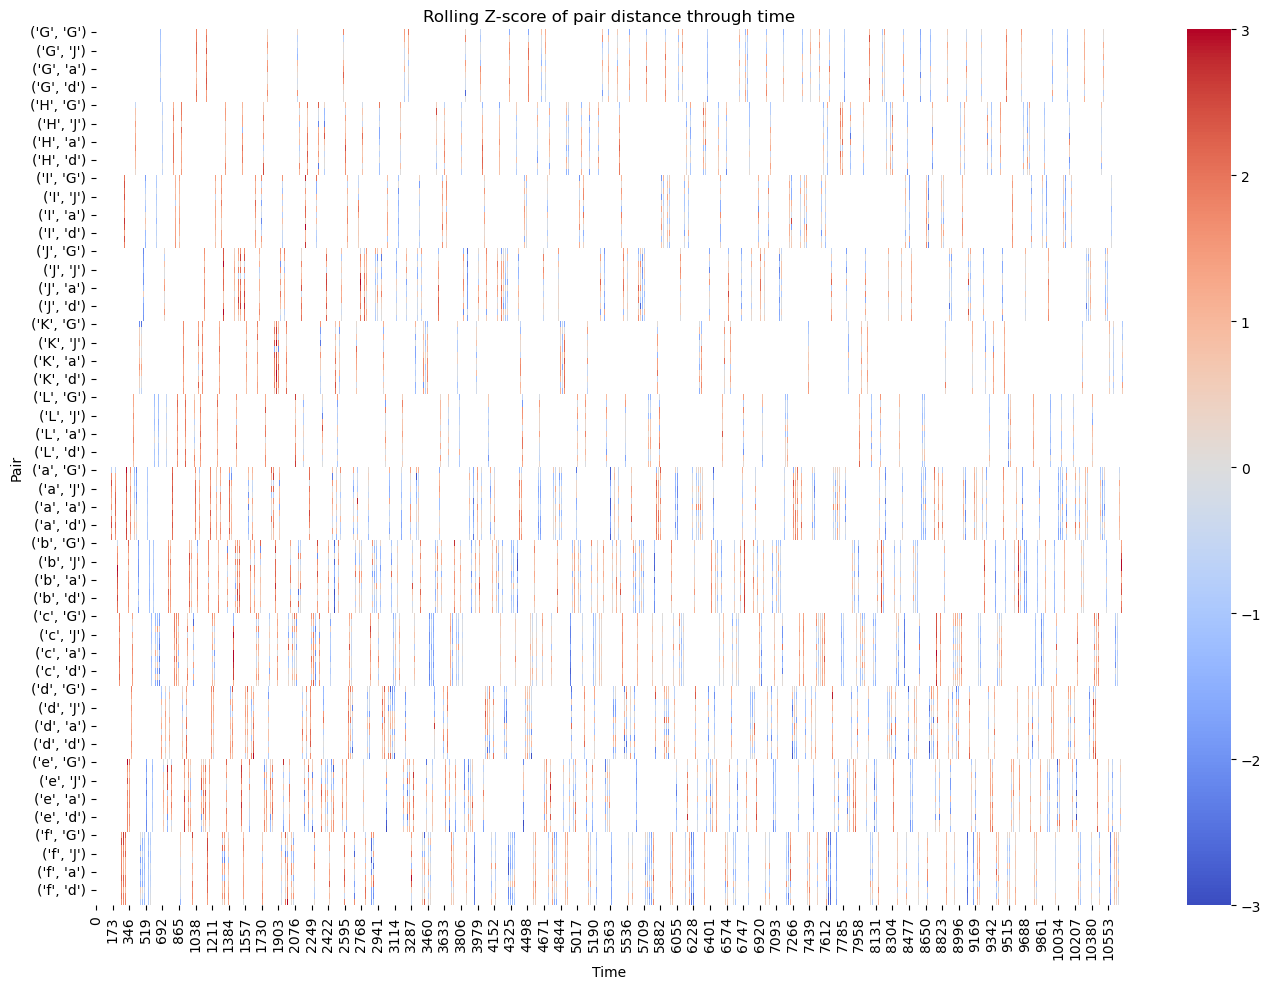

In [68]:
import matplotlib.pyplot as plt
import seaborn as sns

pivot = df.pivot(index="pair", columns="time", values="rolling_z")

plt.figure(figsize=(14, 10))

sns.heatmap(
    pivot,
    cmap="coolwarm",
    center=0,
    vmin=-3,
    vmax=3
)

plt.title("Rolling Z-score of pair distance through time")
plt.xlabel("Time")
plt.ylabel("Pair")

plt.tight_layout()
plt.show()

## Training on multiple models for similarity assessment

In [19]:
#all_models = []

#for i in range(30):
    
#   random.shuffle(sequences)
#   train_set, test_set = sequences[:120], sequences[120:]
#
#    all_epochs = []
#
#    for i in range(30):
#        res = [elt for elt in train(train_set, model)]
#        all_epochs.append(res)
#        scores = test_model(test_set)
#    
#    all_steps = [step for epoch in all_epochs for step in epoch]
#    
#    percent_correct = {}
#    for position, score in enumerate(scores):
#        percent_correct[position + 1] = round(((score['true'] / (score['true'] + score['false'])) * 100), 2)
#    print(percent_correct)
#
#    all_models.append(all_steps)